In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
amazon = pd.read_csv("../data/processed/amzn_market_clean.csv")
sp500 = pd.read_csv("../data/processed/sp500_market_clean.csv")

amazon["Date"] = pd.to_datetime(amazon["Date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

print("Amazon data shape:", amazon.shape)
print("S&P 500 data shape:", sp500.shape)

print("\nAmazon columns:")
print(amazon.columns.tolist())

print("\nS&P 500 columns:")
print(sp500.columns.tolist())

Amazon data shape: (2011, 8)
S&P 500 data shape: (2011, 9)

Amazon columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return']

S&P 500 columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Cumulative_Return']


In [3]:
# Create a combined dataset using the daily returns

data = pd.DataFrame({
    "Date": amazon["Date"],
    "AMZN_Return": amazon["Daily_Return"],
    "SP500_Return": sp500["Daily_Return"]
})

# Previous-day Amazon return
data["AMZN_Return_Lag1"] = data["AMZN_Return"].shift(1)

# 5-day Amazon return
data["AMZN_Return_5D"] = data["AMZN_Return"].rolling(5).sum()

# 20-day Amazon return
data["AMZN_Return_20D"] = data["AMZN_Return"].rolling(20).sum()

# 20-day rolling volatility
data["AMZN_Volatility_20D"] = data["AMZN_Return"].rolling(20).std()

# S&P 500 previous-day return
data["SP500_Return_Lag1"] = data["SP500_Return"].shift(1)

# S&P 500 5-day return
data["SP500_Return_5D"] = data["SP500_Return"].rolling(5).sum()

print(data.head(10))

        Date  AMZN_Return  SP500_Return  AMZN_Return_Lag1  AMZN_Return_5D  \
0 2018-01-02          NaN           NaN               NaN             NaN   
1 2018-01-03     0.012775      0.006399               NaN             NaN   
2 2018-01-04     0.004476      0.004029          0.012775             NaN   
3 2018-01-05     0.016163      0.007034          0.004476             NaN   
4 2018-01-08     0.014425      0.001662          0.016163             NaN   
5 2018-01-09     0.004676      0.001303          0.014425        0.052514   
6 2018-01-10     0.001301     -0.001112          0.004676        0.041040   
7 2018-01-11     0.017818      0.007034          0.001301        0.054382   
8 2018-01-12     0.022339      0.006750          0.017818        0.060559   
9 2018-01-16    -0.000261     -0.003524          0.022339        0.045874   

   AMZN_Return_20D  AMZN_Volatility_20D  SP500_Return_Lag1  SP500_Return_5D  
0              NaN                  NaN                NaN              Na

In [4]:
# Target: will Amazon's next-day return be positive?

data["Next_Day_Return"] = data["AMZN_Return"].shift(-1)

data["Target"] = (data["Next_Day_Return"] > 0).astype(int)

print(data[[
    "Date",
    "AMZN_Return",
    "Next_Day_Return",
    "Target"
]].head(10))

        Date  AMZN_Return  Next_Day_Return  Target
0 2018-01-02          NaN         0.012775       1
1 2018-01-03     0.012775         0.004476       1
2 2018-01-04     0.004476         0.016163       1
3 2018-01-05     0.016163         0.014425       1
4 2018-01-08     0.014425         0.004676       1
5 2018-01-09     0.004676         0.001301       1
6 2018-01-10     0.001301         0.017818       1
7 2018-01-11     0.017818         0.022339       1
8 2018-01-12     0.022339        -0.000261       0
9 2018-01-16    -0.000261        -0.007556       0


In [5]:
# Features used by the machine-learning models

features = [
    "AMZN_Return_Lag1",
    "AMZN_Return_5D",
    "AMZN_Return_20D",
    "AMZN_Volatility_20D",
    "SP500_Return_Lag1",
    "SP500_Return_5D"
]

# Remove rows where the next-day return does not exist
data = data[data["Next_Day_Return"].notna()].copy()

# Remove rows with missing feature values
model_data = data.dropna(subset=features + ["Target"]).copy()

print("Original observations:", len(data))
print("ML observations:", len(model_data))

print("\nMissing values:")
print(model_data[features + ["Target"]].isna().sum())

print("\nTarget distribution:")
print(model_data["Target"].value_counts())

Original observations: 2010
ML observations: 1990

Missing values:
AMZN_Return_Lag1       0
AMZN_Return_5D         0
AMZN_Return_20D        0
AMZN_Volatility_20D    0
SP500_Return_Lag1      0
SP500_Return_5D        0
Target                 0
dtype: int64

Target distribution:
Target
1    1051
0     939
Name: count, dtype: int64


In [6]:
# Define features and target

features = [
    "AMZN_Return_Lag1",
    "AMZN_Return_5D",
    "AMZN_Return_20D",
    "AMZN_Volatility_20D",
    "SP500_Return_Lag1",
    "SP500_Return_5D"
]

X = model_data[features]
y = model_data["Target"]

# Chronological 80/20 train-test split

split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining period:")
print(model_data["Date"].iloc[0], "to", model_data["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(model_data["Date"].iloc[split_index], "to", model_data["Date"].iloc[-1])

Training observations: 1592
Testing observations: 398

Training period:
2018-01-31 00:00:00 to 2024-05-29 00:00:00

Testing period:
2024-05-30 00:00:00 to 2025-12-30 00:00:00


In [7]:
# Train Logistic Regression model

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [8]:
# Evaluate Logistic Regression

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy_logistic)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.5326633165829145

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       186
           1       0.53      1.00      0.70       212

    accuracy                           0.53       398
   macro avg       0.27      0.50      0.35       398
weighted avg       0.28      0.53      0.37       398


Confusion Matrix:


c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"

[[  0 186]
 [  0 212]]


In [9]:
# Train Random Forest model

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

# Predictions
y_pred_rf = random_forest.predict(X_test)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [10]:
# Evaluate Random Forest

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.48743718592964824

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.45      0.45       186
           1       0.52      0.52      0.52       212

    accuracy                           0.49       398
   macro avg       0.49      0.49      0.49       398
weighted avg       0.49      0.49      0.49       398


Confusion Matrix:
[[ 84 102]
 [102 110]]


In [11]:
# Compare model performance

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_rf
    ]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,0.532663
1,Random Forest,0.487437


In [12]:
# Naive majority-class benchmark

majority_class = y_train.mode()[0]

y_pred_baseline = np.full(len(y_test), majority_class)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Majority-class baseline:", majority_class)
print("Baseline accuracy:", baseline_accuracy)

Majority-class baseline: 1
Baseline accuracy: 0.5326633165829145


## 6. Robustness Check: Time-Series Cross-Validation

A single train-test split may give a misleading estimate of model performance.

To test the robustness of the machine-learning models, we use chronological time-series cross-validation. This preserves the temporal order of observations and avoids using future information to predict the past.

In [13]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Logistic Regression
logistic_cv_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=tscv,
    scoring="accuracy"
)

# Random Forest
rf_cv_scores = cross_val_score(
    random_forest,
    X,
    y,
    cv=tscv,
    scoring="accuracy"
)

print("Logistic Regression CV scores:")
print(logistic_cv_scores)

print("\nLogistic Regression mean accuracy:")
print(logistic_cv_scores.mean())

print("\nRandom Forest CV scores:")
print(rf_cv_scores)

print("\nRandom Forest mean accuracy:")
print(rf_cv_scores.mean())

Logistic Regression CV scores:
[0.55287009 0.51057402 0.49546828 0.52265861 0.5347432 ]

Logistic Regression mean accuracy:
0.523262839879154

Random Forest CV scores:
[0.50755287 0.50453172 0.47734139 0.43806647 0.49546828]

Random Forest mean accuracy:
0.4845921450151057


## 7. Additional Model Evaluation: ROC-AUC

Accuracy measures the percentage of correct classifications, but it does not show how well the model separates positive and negative outcomes.

ROC-AUC provides an additional measure of classification quality. A value close to 0.50 indicates performance similar to random classification.

In [14]:
from sklearn.metrics import roc_auc_score

# Logistic Regression probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest probabilities
rf_probabilities = random_forest.predict_proba(X_test)[:, 1]

# ROC-AUC
logistic_auc = roc_auc_score(y_test, logistic_probabilities)
rf_auc = roc_auc_score(y_test, rf_probabilities)

print("Logistic Regression ROC-AUC:", logistic_auc)
print("Random Forest ROC-AUC:", rf_auc)

Logistic Regression ROC-AUC: 0.5501115844998985
Random Forest ROC-AUC: 0.4922905254615541


## 8. Investment Strategy Backtest

Statistical prediction accuracy does not necessarily translate into investment performance.

To evaluate the economic relevance of the machine-learning model, we construct a simple long-only strategy. The strategy invests in Amazon when the model predicts a positive next-day return and remains in cash otherwise.

The strategy is evaluated against a buy-and-hold Amazon benchmark using cumulative returns, annualized return, annualized volatility, Sharpe ratio, and maximum drawdown.

In [15]:
# Generate probability of Amazon going UP
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Use a slightly higher threshold
threshold = 0.53

# Create trading signals
# 1 = invest in Amazon
# 0 = stay in cash
logistic_predictions = (
    logistic_probabilities >= threshold
).astype(int)

# Create a copy of the test data
strategy_data = model_data.iloc[split_index:].copy()

# Store trading signal
strategy_data["Signal"] = logistic_predictions

print("Threshold:", threshold)
print("\nPrediction distribution:")
print(pd.Series(logistic_predictions).value_counts())

# Strategy return
strategy_data["Strategy_Return"] = (
    strategy_data["Signal"] * strategy_data["Next_Day_Return"]
)

# Buy-and-hold Amazon return
strategy_data["Buy_Hold_Return"] = strategy_data["Next_Day_Return"]

# Cumulative returns
strategy_data["Strategy_Cumulative"] = (
    1 + strategy_data["Strategy_Return"]
).cumprod()

strategy_data["Buy_Hold_Cumulative"] = (
    1 + strategy_data["Buy_Hold_Return"]
).cumprod()

print("Final strategy value:", strategy_data["Strategy_Cumulative"].iloc[-1])
print("Final buy-and-hold value:", strategy_data["Buy_Hold_Cumulative"].iloc[-1])

Threshold: 0.53

Prediction distribution:
0    296
1    102
Name: count, dtype: int64
Final strategy value: 1.1132096468706028
Final buy-and-hold value: 1.2871960623271999


In [16]:
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", logistic_probabilities.min())
print("Maximum probability:", logistic_probabilities.max())
print("Average probability:", logistic_probabilities.mean())

print("\nPrediction distribution:")
print(pd.Series(logistic_predictions).value_counts())

Minimum probability: 0.5101690828247194
Maximum probability: 0.5530459002163434
Average probability: 0.5269905605997524

Prediction distribution:
0    296
1    102
Name: count, dtype: int64


## 9. Investment Performance Evaluation

The machine-learning strategy is compared with a buy-and-hold Amazon strategy using standard investment-performance metrics.

The evaluation includes annualized return, annualized volatility, Sharpe ratio, and maximum drawdown.

In [17]:
# Number of trading days per year
TRADING_DAYS = 252

# -----------------------------
# Annualized returns
# -----------------------------

strategy_total_return = (
    strategy_data["Strategy_Cumulative"].iloc[-1] - 1
)

buy_hold_total_return = (
    strategy_data["Buy_Hold_Cumulative"].iloc[-1] - 1
)

number_of_days = len(strategy_data)

strategy_annual_return = (
    (1 + strategy_total_return) ** (TRADING_DAYS / number_of_days) - 1
)

buy_hold_annual_return = (
    (1 + buy_hold_total_return) ** (TRADING_DAYS / number_of_days) - 1
)


# -----------------------------
# Annualized volatility
# -----------------------------

strategy_volatility = (
    strategy_data["Strategy_Return"].std() * np.sqrt(TRADING_DAYS)
)

buy_hold_volatility = (
    strategy_data["Buy_Hold_Return"].std() * np.sqrt(TRADING_DAYS)
)


# -----------------------------
# Sharpe ratio
# -----------------------------

strategy_sharpe = (
    strategy_annual_return / strategy_volatility
)

buy_hold_sharpe = (
    buy_hold_annual_return / buy_hold_volatility
)


# -----------------------------
# Maximum drawdown
# -----------------------------

strategy_peak = strategy_data["Strategy_Cumulative"].cummax()

strategy_drawdown = (
    strategy_data["Strategy_Cumulative"] / strategy_peak - 1
)

strategy_max_drawdown = strategy_drawdown.min()


buy_hold_peak = strategy_data["Buy_Hold_Cumulative"].cummax()

buy_hold_drawdown = (
    strategy_data["Buy_Hold_Cumulative"] / buy_hold_peak - 1
)

buy_hold_max_drawdown = buy_hold_drawdown.min()


# -----------------------------
# Summary table
# -----------------------------

performance = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown"
    ],
    "ML Strategy": [
        strategy_total_return,
        strategy_annual_return,
        strategy_volatility,
        strategy_sharpe,
        strategy_max_drawdown
    ],
    "Buy & Hold": [
        buy_hold_total_return,
        buy_hold_annual_return,
        buy_hold_volatility,
        buy_hold_sharpe,
        buy_hold_max_drawdown
    ]
})

performance

,Metric,ML Strategy,Buy & Hold
0,Total Return,0.113210,0.287196
1,Annualized Return,0.070264,0.173338
2,Annualized Volatility,0.208625,0.328475
3,Sharpe Ratio,0.336795,0.527707
4,Maximum Drawdown,-0.192420,-0.308766


## 10. Strategy Performance vs Buy & Hold

The cumulative performance of the machine-learning strategy is compared with a buy-and-hold Amazon benchmark over the out-of-sample testing period.

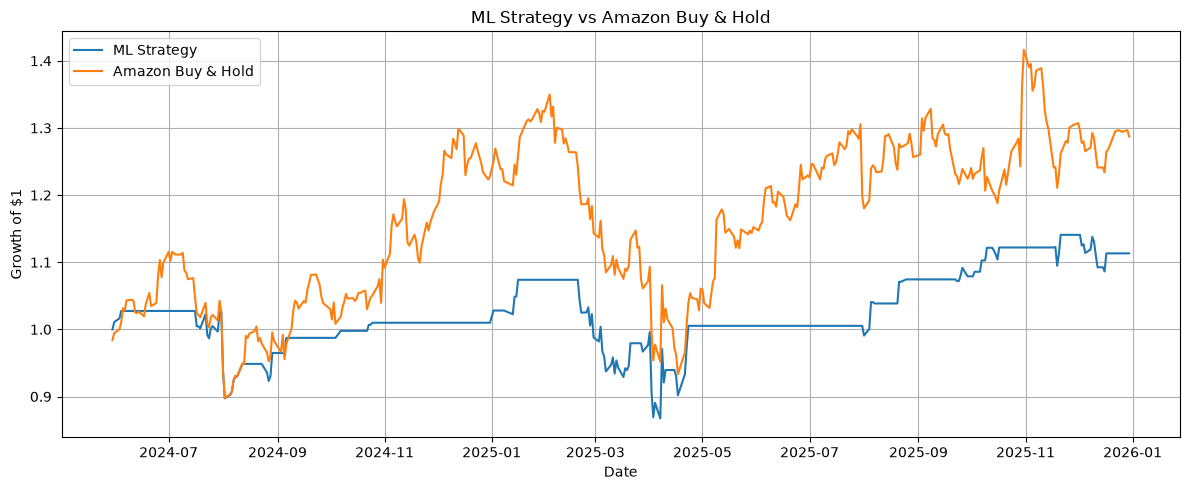

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    strategy_data["Date"],
    strategy_data["Strategy_Cumulative"],
    label="ML Strategy"
)

plt.plot(
    strategy_data["Date"],
    strategy_data["Buy_Hold_Cumulative"],
    label="Amazon Buy & Hold"
)

plt.title("ML Strategy vs Amazon Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [19]:
# ============================================
# 7. Export ML Strategy Results
# ============================================

# Select the columns needed for the final analysis
results_data = strategy_data[
    [
        "Date",
        "Next_Day_Return",
        "Signal",
        "Strategy_Return",
        "Buy_Hold_Return",
        "Strategy_Cumulative",
        "Buy_Hold_Cumulative"
    ]
].copy()

# Save the results
output_path = "../data/processed/amzn_ml_strategy_results.csv"

results_data.to_csv(output_path, index=False)

print("ML strategy results saved successfully.")
print("File:", output_path)
print("Rows:", len(results_data))

print("\nFirst 5 rows:")
display(results_data.head())

ML strategy results saved successfully.
File: ../data/processed/amzn_ml_strategy_results.csv
Rows: 398

First 5 rows:


,Date,Next_Day_Return,Signal,Strategy_Return,Buy_Hold_Return,Strategy_Cumulative,Buy_Hold_Cumulative
1612,2024-05-30,-0.016061,0,-0.000000,-0.016061,1.000000,0.983939
1613,2024-05-31,0.010768,1,0.010768,0.010768,1.010768,0.994535
1614,2024-06-03,0.005607,1,0.005607,0.005607,1.016436,1.000111
1615,2024-06-04,0.010817,1,0.010817,0.010817,1.027431,1.010930
1616,2024-06-05,0.020521,0,0.000000,0.020521,1.027431,1.031675


In [20]:
# ============================================
# 8. Export Model Performance Summary
# ============================================

model_performance = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Buy & Hold"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, random_forest.predict(X_test)),
        baseline_accuracy
    ],
    
    "ROC_AUC": [
        logistic_auc,
        rf_auc,
        None
    ],
    
    "Total_Return": [
        strategy_data["Strategy_Cumulative"].iloc[-1] - 1,
        None,
        strategy_data["Buy_Hold_Cumulative"].iloc[-1] - 1
    ]
})

# Save the summary
performance_path = "../data/processed/model_performance_summary.csv"

model_performance.to_csv(
    performance_path,
    index=False
)

print("Model performance summary saved successfully.")
print("File:", performance_path)

display(model_performance)

Model performance summary saved successfully.
File: ../data/processed/model_performance_summary.csv


,Model,Accuracy,ROC_AUC,Total_Return
0,Logistic Regression,0.497487,0.550112,0.113210
1,Random Forest,0.487437,0.492291,NaN
2,Buy & Hold,0.532663,NaN,0.287196


## 11. Investment Relevance

The machine-learning strategy was evaluated not only according to its predictive performance, but also according to its potential investment value.

The backtest shows that the ML strategy generated a positive return, but it underperformed the Buy & Hold benchmark in terms of total and annualized return. However, the ML strategy also exhibited lower volatility and a smaller maximum drawdown.

This indicates a trade-off between return and risk. The ML strategy did not outperform a simple passive investment strategy during the tested period, but it provided a more conservative risk profile.

From an investment perspective, the results suggest that the machine-learning model may have some value as a risk-management or signal-generation tool, but the evidence is not strong enough to conclude that it is superior to Buy & Hold.

The strategy should therefore be considered as an experimental quantitative approach rather than a replacement for a passive investment strategy. Further testing on different time periods, market conditions, assets, and transaction-cost assumptions would be necessary before considering real-world implementation.

### Key Investment Findings

- The ML strategy generated a positive cumulative return.
- Buy & Hold achieved a higher overall return during the backtest period.
- The ML strategy experienced lower volatility than Buy & Hold.
- The ML strategy had a smaller maximum drawdown.
- The risk-adjusted performance advantage of the ML strategy was not sufficient to compensate for its lower return.
- The results demonstrate the importance of evaluating both return and risk when assessing an investment strategy.

### Investment Conclusion

Overall, the machine-learning strategy demonstrates that predictive models can be transformed into an investment strategy, but predictive performance alone does not guarantee superior investment performance. In this study, Buy & Hold remained the stronger strategy in terms of return, while the ML strategy offered a relatively lower-risk alternative.

These findings highlight the importance of robustness testing, risk management, and comparison with simple benchmarks when evaluating quantitative investment strategies.